# Experiment 2: risk in particular releases

The adversary knows that the target is in the release and knows the target's race, and wants to infer the target's marital status. For releases of $n = 10^3$ and $n = 10^5$ records, 1000 histograms $h \sim \mathrm{Mult}_n(\theta)$ are drawn. In each group $q$, the risk $r_q(h)$ (Section 5.1) is computed over the histograms in which the group appears; over all the groups, the fraction of inferred individuals $\bar r(h)$ is compared with its expected value $\mathbb{E}[\bar r(h)]$ (Proposition 5.2(a)).

This notebook produces **Figure 2** of the paper: `figures/figure2.pdf`.

QID: race (`RAC1P`); sensitive attribute: marital status (`MAR`). The code of the experiment is in `release_risks.py`.

In [1]:
import release_risks as rr
from build_pums2010 import build_dataset
from common import load_population

data_path = build_dataset()  # downloads and extracts the 2010 ACS PUMS on the first run

Population: 3,061,692 records with no N/A in RAC1P, MAR


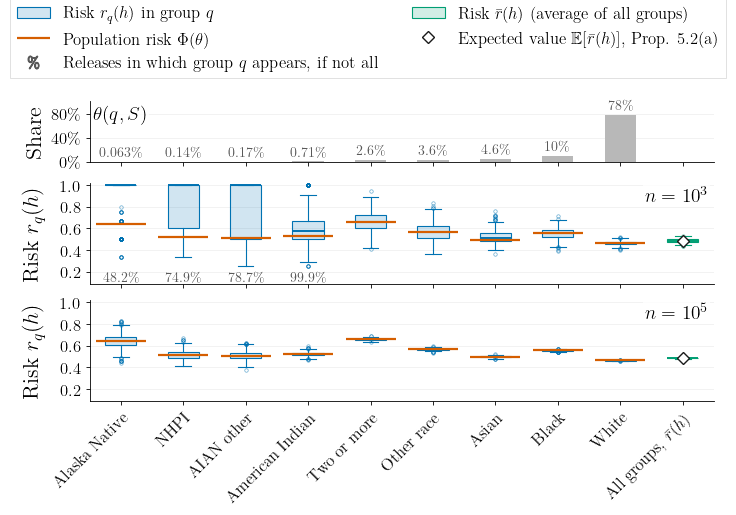

In [2]:
qids, sensitive = ["RAC1P"], "MAR"  # QID: race; sensitive attribute: marital status
sizes = [10**3, 10**5]  # numbers of records n of the releases, a panel each

theta = load_population(data_path, qids, sensitive)
rr.plot(theta, sizes, "figures/figure2.pdf", figsize=(7, 5))

## Numbers quoted in the text

The range and the average of the risk $r_q(h)$ for $n = 10^5$ in the smallest group (Alaska Natives) and in the largest (White), and the average of $\bar r(h)$ over the releases against its expected value.

In [3]:
# The risk r_q(h) in the smallest and the largest group over the releases of n = 10^5 records (the
# mean is over the releases in which the group appears)
n = sizes[1]
table = rr.risk_table(theta, n).set_index("group")
table["mean"] = rr.release_risks(theta, n).mean().to_numpy()
table.loc[["Alaska Native", "White"], ["share", "base-rate risk", "present", "min", "mean", "max"]]

,share,base-rate risk,present,min,mean,max
group,,,,,,
Alaska Native,0.000628,0.638918,1.0,0.437500,0.639772,0.825000
White,0.776574,0.463918,1.0,0.456919,0.463954,0.470192


In [4]:
# Proposition 5.2(a): the mean of the fraction of inferred individuals rbar(h) over the releases,
# with its standard error, and its expected value, computed exactly
rr.fraction_table(theta, sizes)

,base-rate risk,expected,sampled,standard error
n,,,,
1000,0.484674,0.487225,0.487515,0.000499
100000,0.484674,0.484675,0.484704,0.000053


In [5]:
# The boxes of the panel n = 10^3: the risk r_q(h) in each group over the releases, and the share of
# the releases in which the group appears ("present")
rr.risk_table(theta, sizes[0])

,group,share,mu,base-rate risk,present,min,q1,median,q3,max
0,Alaska Native,0.000628,0.627757,0.638918,0.482,0.333333,1.000000,1.000000,1.000000,1.000000
1,NHPI,0.001438,1.437767,0.517265,0.749,0.333333,0.600000,1.000000,1.000000,1.000000
2,AIAN other,0.001691,1.690568,0.508114,0.787,0.250000,0.500000,1.000000,1.000000,1.000000
3,American Indian,0.007089,7.089217,0.526146,0.999,0.250000,0.500000,0.571429,0.666667,1.000000
4,Two or more,0.026067,26.066959,0.658297,1.000,0.409091,0.600000,0.656250,0.724138,0.947368
5,Other race,0.036479,36.479176,0.566381,1.000,0.366667,0.512821,0.566667,0.622222,0.837838
6,Asian,0.045842,45.841646,0.496826,1.000,0.368421,0.480000,0.513514,0.554067,0.761905
7,Black,0.104193,104.193368,0.557394,1.000,0.388889,0.522423,0.556652,0.586598,0.709677
8,White,0.776574,776.573542,0.463918,1.000,0.402926,0.452520,0.463824,0.476893,0.519674
